# Segment an aerial LiDAR survey

This notebook will guide you on how to train a semantic segmentation model on the tiles of an aerial LiDAR survey and run it over whole tiles, from `.laz` files in to `.laz` files out.

The survey is the [LiDAR HD](https://geoservices.ign.fr/lidarhd) coverage of France by IGN: 1 km × 1 km tiles of about 20 million points, delivered as compressed LAZ with a per-point classification. A tile does not fit one forward pass of a point network, so the workflow is the one every survey-scale pipeline ends up with: cut the tiles into blocks, train on the blocks, and stitch the block predictions back into whole tiles with an inferer.

## Setup

In [1]:
# On Colab:
# !pip install "torch-pointcloud" "laspy[lazrs]"
# !pip install pyg-lib -f https://data.pyg.org/whl/torch-2.10.0+cu128.html

In [2]:
import math
import time
from pathlib import Path

import laspy
import numpy as np
import torch

import torch_pointcloud as tp
import torch_pointcloud.transforms as T

torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch-pointcloud", tp.__version__, "| laspy", laspy.__version__, "| device:", DEVICE)

torch-pointcloud 0.0.2 | laspy 2.7.0 | device: cuda


## Helpers

A few plotting helpers used throughout the notebook. A tile has too many points to scatter, so the figures draw a fixed subsample and say so in their titles.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Transparent canvas and gray ink, so the same figure reads on a light and on a dark page.
INK = "#7a7a7a"
plt.rcParams.update({"figure.dpi": 100, "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
                     "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": INK})

MAP, OBLIQUE = (88, -90), (48, -62)  # elevation and azimuth: straight down, and from the south-west


def figure(columns, height=5.0):
    fig = plt.figure(figsize=(12, height))
    fig.subplots_adjust(left=0.0, right=1.0, top=0.95, bottom=0.08, wspace=0.0)
    return fig


def show_cloud(pos, color, *, ax=None, title=None, size=0.3, view=MAP, cmap=None, zoom=1.25):
    if ax is None:
        ax = figure(1).add_subplot(projection="3d")

    p = pos.cpu().numpy()
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=color, s=size, linewidths=0, depthshade=False, cmap=cmap)
    ax.view_init(elev=view[0], azim=view[1])
    ax.set_box_aspect(np.ptp(p, axis=0), zoom=zoom)
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)
    return ax


def class_legend(fig, names, colors):
    fig.legend(handles=[Patch(color=c, label=n) for n, c in zip(names, colors)], loc="lower center", ncol=len(names), frameon=False, fontsize=9)


def bar_chart(ax, names, values, colors, ylabel, limit=None):
    ax.bar(names, values, color=colors, width=0.62)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}" if v < 10 else f"{v:.0f}", ha="center", va="bottom", fontsize=8)

    ax.set(ylabel=ylabel, ylim=(0, limit))
    ax.spines[["top", "right"]].set_visible(False)


def square(pos, corner, side):
    inside = (pos[:, :2] >= torch.tensor(corner)).all(dim=1) & (pos[:, :2] < torch.tensor(corner) + side).all(dim=1)
    return inside.nonzero().squeeze(1)

## Data

Six neighboring tiles of central Paris sit under `data/LidarHD/raw/`, downloaded from the [IGN portal](https://geoservices.ign.fr/lidarhd) (the classified tiles, `PTS_C` in the current naming). Four tiles train the model, one validates it, and one is held out for the whole-tile run at the end. The library has no LiDAR HD dataset, so this notebook reads the files with [`laspy`](https://laspy.readthedocs.io/): the `lazrs` backend decompresses a 19 million point tile in about a second.

In [ ]:
ROOT = Path("data")
TRAIN_TILES = ["LHD_FXX_0651_6862", "LHD_FXX_0651_6863", "LHD_FXX_0653_6862", "LHD_FXX_0649_6860"]
VAL_TILES = ["LHD_FXX_0653_6863"]
TEST_TILE = "LHD_FXX_0651_6861"


def read_tile(path):
    las = laspy.read(path)
    origin = np.floor(np.asarray(las.header.mins) / 1000.0) * 1000.0
    origin[2] = 0.0
    pos = np.stack([las.x, las.y, las.z], axis=1) - origin
    return {
        "pos": torch.from_numpy(pos.astype(np.float32)),
        "intensity": torch.from_numpy(np.asarray(las.intensity, dtype=np.float32)).unsqueeze(1),
        "return_number": torch.from_numpy(np.asarray(las.return_number, dtype=np.float32)).unsqueeze(1),
        "number_of_returns": torch.from_numpy(np.asarray(las.number_of_returns, dtype=np.float32)).unsqueeze(1),
        "segment": torch.from_numpy(np.asarray(las.classification, dtype=np.int64)),
    }


path = next((ROOT / "LidarHD" / "raw").glob(f"{TEST_TILE}*.laz"))
tile = read_tile(path)
pos = tile["pos"]
print(f"{path.name}: {len(pos):,} points, {len(pos) / 1e6:.1f} per m²")
for axis, name in enumerate("xyz"):
    print(f"  {name}: {float(pos[:, axis].min()):7.2f} to {float(pos[:, axis].max()):7.2f} m")
codes, counts = torch.unique(tile["segment"], return_counts=True)
for code_, count in zip(codes.tolist(), counts.tolist()):
    print(f"  code {code_:3d}: {100 * count / len(pos):5.2f}%")

LHD_FXX_0651_6861_PTS_LAMB93_IGN69.copc.laz: 19,362,944 points, 19.4 per m²
  x:    0.00 to 1000.00 m
  y:    0.00 to 1000.00 m
  z:   31.85 to  117.94 m
  code   1: 10.40%
  code   2: 38.85%
  code   3:  0.43%
  code   4:  1.10%
  code   5: 19.53%
  code   6: 29.34%
  code  64:  0.06%
  code  65:  0.09%
  code  67:  0.20%


19.4 million points over exactly one square kilometer, 19 per m², with 86 m of relief between the Seine and the rooftops. The file stores Lambert-93 coordinates, so $x \approx 651\,000$ m and $y \approx 6\,861\,000$ m. A float32 number near $6\,861\,000$ has a spacing of $0.5$ m between its neighbors, which is why `read_tile` subtracts the tile corner *before* casting: a survey tile kept in projected coordinates as float32 loses the geometry of the scan.

The `classification` field is the IGN read of every point, on the LiDAR HD code list. This notebook learns the five classes that cover 90 % of the points and ignores the rest, which includes the 10 % that IGN leaves unclassified (vehicles, street furniture, anything that is not one of the named classes):

| LiDAR HD code | meaning | class here |
| --- | --- | --- |
| 2 | ground | 0, ground |
| 3 | low vegetation, under 50 cm | 1, low vegetation |
| 4 | medium vegetation, 50 cm to 1.5 m | 2, medium vegetation |
| 5 | high vegetation, above 1.5 m | 3, high vegetation |
| 6 | building | 4, building |
| 1, 9, 17, 64, 65, 66, 67 | unclassified, water, bridge, permanent above-ground, artifacts, virtual points, miscellaneous | ignored |

In [5]:
CLASSES = ["ground", "low vegetation", "medium vegetation", "high vegetation", "building"]
CLASS_COLOR = np.array(["#ff5722", "#2f7bbf", "#3fa66a", "#a862c4", "#e0a600", "#c4c4c4"])  # the five classes, then gray for the rest
LIDARHD_TO_CLASS = {2: 0, 3: 1, 4: 2, 5: 3, 6: 4}
IGNORE = 255

relabel = T.Relabel(keys="segment", labels=LIDARHD_TO_CLASS, default=IGNORE)
target = relabel({"segment": tile["segment"]})["segment"]
print("labeled points:", f"{100 * float((target != IGNORE).float().mean()):.1f}%")

labeled points: 89.2%


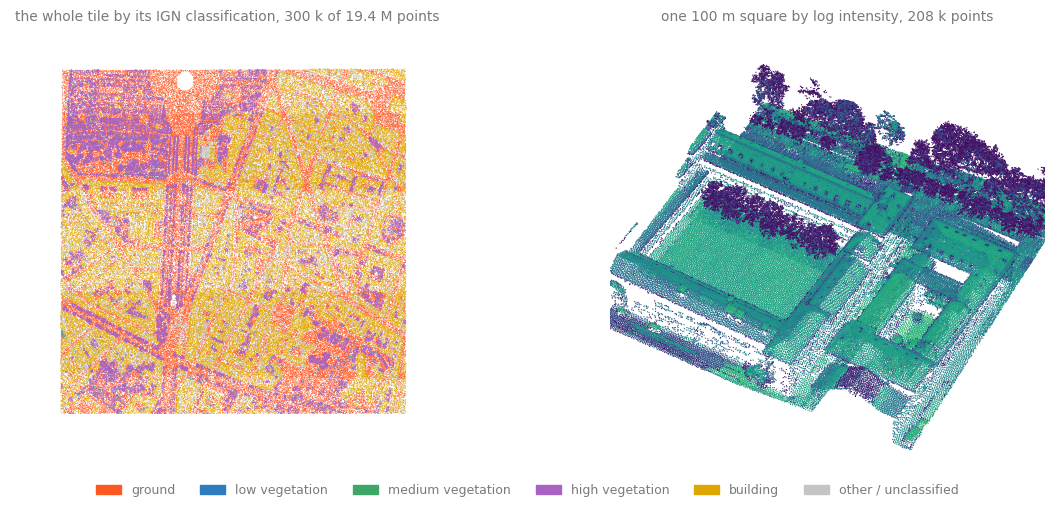

In [6]:
drawn = torch.randperm(len(pos))[:300_000]
detail = square(pos, (200.0, 600.0), 100.0)

fig = figure(2)
show_cloud(pos[drawn], CLASS_COLOR[target[drawn].clamp(max=5)], ax=fig.add_subplot(121, projection="3d"), title=f"the whole tile by its IGN classification, {len(drawn) / 1e3:.0f} k of {len(pos) / 1e6:.1f} M points")
show_cloud(pos[detail], torch.log1p(tile["intensity"][detail, 0]), ax=fig.add_subplot(122, projection="3d"), title=f"one 100 m square by log intensity, {len(detail) / 1e3:.0f} k points", size=0.8, view=OBLIQUE, cmap="viridis", zoom=1.3)
class_legend(fig, CLASSES + ["other / unclassified"], CLASS_COLOR)

![The tile by IGN class and a 100 m square by intensity](../assets/tutorials/survey_tile.png)

Seen from above the tile is a map: streets in orange, roofs in yellow, the trees of the boulevards and courtyards in purple. The square on the right is one Haussmann block at full resolution, colored by the log of the return intensity.

## From tiles to training blocks

A point network trains on samples of a few tens of thousands of points, so a tile has to be cut. This notebook uses 50 m squares, the same receptive field as IGN's own [Myria3D](https://github.com/IGNF/myria3d) pipeline: at 19 points per m² a block holds about 40 000 points, and 400 of them tile a square kilometer.

`PointCloudDataset` gives a dataset the `raw/` + `processed/` layout of the built-in ones. The cache below writes one `.pt` file per block the first time a tile is requested, so an epoch never decompresses a LAZ. Cutting five tiles takes about a minute and a half.

In [ ]:
from torch_pointcloud.datasets import PointCloudDataset


class LidarHD(PointCloudDataset):
    def __init__(self, root, tiles, block_size=50.0, min_points=500, transform=None):
        super().__init__(root)
        self.tiles = list(tiles)
        self.block_size = block_size
        self.min_points = min_points
        self.transform = transform
        for tile in self.tiles:
            if not (Path(self.processed_dir) / tile).exists():
                self.process(tile)
        self.files = sorted(path for tile in self.tiles for path in (Path(self.processed_dir) / tile).glob("*.pt"))

    def process(self, tile):
        data = read_tile(next(Path(self.raw_dir).glob(f"{tile}*.laz")))
        cell = torch.div(data["pos"][:, :2], self.block_size, rounding_mode="floor").long()
        block, inverse, counts = torch.unique(cell, dim=0, return_inverse=True, return_counts=True)
        order = torch.argsort(inverse, stable=True)
        out_dir = Path(self.processed_dir) / tile
        out_dir.mkdir(parents=True, exist_ok=True)
        for b, (start, count) in enumerate(zip(counts.cumsum(0) - counts, counts)):
            if count < self.min_points:
                continue
            index = order[start : start + count]
            torch.save({k: v[index] for k, v in data.items()}, out_dir / f"{int(block[b, 0]):02d}_{int(block[b, 1]):02d}.pt")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        data = torch.load(self.files[i], weights_only=True)
        return self.transform(data) if self.transform is not None else data


train_dataset = LidarHD(ROOT, TRAIN_TILES)
val_dataset = LidarHD(ROOT, VAL_TILES)
print(f"train blocks: {len(train_dataset):,} | val blocks: {len(val_dataset):,}")
block = train_dataset[0]
print({k: (tuple(v.shape), str(v.dtype)) for k, v in block.items()})

train blocks: 1,587 | val blocks: 400
{'pos': ((30778, 3), 'torch.float32'), 'intensity': ((30778, 1), 'torch.float32'), 'return_number': ((30778, 1), 'torch.float32'), 'number_of_returns': ((30778, 1), 'torch.float32'), 'segment': ((30778,), 'torch.int64')}


1587 training blocks and 400 validation blocks, each a dict of the same keys as a tile. `torch.unique` over the integer cell coordinates is the whole tiling: it names the block of every point and, with `return_inverse`, sorts the points by block in one pass.

## The block pipeline

Every block goes through the same `Compose` before it reaches the network, whether it comes from the training set, the validation set or the sliding window at the end:

- **Labels** map to the five classes with `Relabel`; everything else becomes `IGNORE`.
- **Coordinates** are centered on the block in $x$ and $y$ with `Shift`, so the network never sees where in the tile a block came from.
- **Features** are what the survey measured, which a point network cannot read off the geometry: the height above the block's floor (`AxisMinOffset` at the 1st percentile, which ignores the odd point below ground), the log of the intensity, and the return number and count. `Cat` stacks them into a $(N, 4)$ tensor `x`.
- **A 0.25 m grid** (`Voxelize`) thins the block to one point per cell, the resolution Myria3D trains at. The eval pipeline records the inverse map so predictions come back at full resolution; the train pipeline instead picks a random point per cell every epoch.
- **Augmentation** is a rotation about the vertical, a flip and a small jitter, and only in the train pipeline. An aerial survey has no preferred heading.

The label transforms carry `allow_missing_keys=True`, so the same eval pipeline runs on a tile that has no classification at all.

In [8]:
def log_intensity(data):
    data = dict(data)
    data["intensity"] = torch.log1p(data["intensity"]) / math.log1p(65535.0)
    return data


features = T.Compose([
    T.Relabel(keys="segment", labels=LIDARHD_TO_CLASS, default=IGNORE, allow_missing_keys=True),
    T.Shift(keys="pos", method="bbox", axes=[0, 1]),
    T.AxisMinOffset(keys="pos", axis=2, quantile=0.01, dst_keys="height"),
    log_intensity,
    T.Scale(keys=["return_number", "number_of_returns"], scale=0.1),
    T.Cat(keys=["height", "intensity", "return_number", "number_of_returns"], dst_key="x", dim=1),
])
eval_transform = T.Compose([
    features,
    T.Voxelize(pos_key="pos", pos_reduce="mean", size=0.25, keys=["x", "segment"], dst_inverse_key="inverse", allow_missing_keys=True),
    T.KeepItems(keys=["pos", "x", "segment", "inverse"], allow_missing_keys=True),
])
train_transform = T.Compose([
    features,
    T.Voxelize(pos_key="pos", pos_reduce="mean", size=0.25, keys=["x", "segment"], random_first=True),
    T.RandomRotate(keys="pos", angle_range=(-180.0, 180.0), axis=2),
    T.RandomFlip(keys="pos", axes=(0, 1), p=0.5),
    T.RandomJitter(keys="pos", sigma=0.02, clip=0.05),
    T.KeepItems(keys=["pos", "x", "segment"]),
])

sample = eval_transform(block)
print({k: tuple(v.shape) for k, v in sample.items()})
print("x row 0:", [round(float(v), 3) for v in sample["x"][0]])

{'pos': (24670, 3), 'x': (24670, 4), 'segment': (24670,), 'inverse': (30778,)}
x row 0: [-0.11, 0.412, 0.2, 0.2]


The first block goes from 40 591 points to 24 670 grid cells, and `inverse` keeps the 40 591-long map back. A `Compose` accepts any callable, which is what `log_intensity` is: a transform the library does not have is three lines, not a subclass.

## Model

RandLA-Net is the architecture Myria3D runs in production, and for the same reasons it fits here: it takes raw packed points, it needs nothing beyond `pyg-lib`, and a block of 25 000 points is one forward pass. The library's constructor is explicit, so the whole configuration is on the page: four encoder blocks, random decimation by four between them, 16 neighbors, and a four-channel input.

In [9]:
from torch_pointcloud.models import RandLANetSegmentation

model = RandLANetSegmentation(
    in_channels=4,
    num_classes=len(CLASSES),
    stem_channels=8,
    encoder_channels=[32, 128, 256, 512],
    fp_channels=[256, 128, 32, 32],
    head_channels=[64, 32],
    aggr_channels=512,
    decimation=4,
    num_neighbors=16,
    dropout=0.5,
).to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

1.24M parameters


The loss is a cross-entropy weighted by the inverse square root of each class's frequency: ground and building are 70 % of the labeled points, low vegetation is 0.3 %. `ignore_index` drops the points that are not one of the five classes.

In [10]:
from torch_pointcloud.utils.data import PointCloudDataLoader

BATCH_SIZE, EPOCHS, LR = 8, 12, 2e-3

train_dataset.transform, val_dataset.transform = train_transform, eval_transform
train_loader = PointCloudDataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=6)
val_loader = PointCloudDataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=6)

counts = torch.zeros(len(CLASSES))
for i in range(0, len(train_dataset), 16):
    segment = train_dataset[i]["segment"]
    counts += torch.bincount(segment[segment != IGNORE], minlength=len(CLASSES)).float()
weights = 1.0 / (counts / counts.sum()).sqrt()
weights = weights / weights.mean()
print("class weights:", {name: round(float(w), 2) for name, w in zip(CLASSES, weights)})

criterion = torch.nn.CrossEntropyLoss(weight=weights.to(DEVICE), ignore_index=IGNORE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.1)
print(len(train_loader), "steps per epoch")

class weights: {'ground': 0.24, 'low vegetation': 2.52, 'medium vegetation': 1.61, 'high vegetation': 0.39, 'building': 0.24}
198 steps per epoch


## Training

The loop is plain PyTorch. A batch is eight blocks packed into one $(N, 4)$ feature tensor, one $(N, 3)$ position tensor and one $(N,)$ batch index, about 280 000 points, and the model returns one logit vector per point. Validation scores at grid resolution, the way training sees the data; the whole-tile run below scores at full resolution.

In [11]:
from tqdm.auto import tqdm

from torch_pointcloud.metrics import accuracy, confusion_matrix, intersection_over_union


def train_one_epoch(model, dataloader, optimizer, scheduler, criterion):
    model.train()
    total_loss, total_points = 0.0, 0
    for data in tqdm(dataloader, desc="Training", leave=False):
        x, pos, batch, target = (data[k].to(DEVICE) for k in ("x", "pos", "batch", "segment"))
        optimizer.zero_grad()
        loss = criterion(model(x, pos, batch), target)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(target)
        total_points += len(target)
    return total_loss / total_points


@torch.no_grad()
def evaluate(model, dataloader):
    model.eval()
    cm = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.long)
    for data in tqdm(dataloader, desc="Evaluating", leave=False):
        x, pos, batch, target = (data[k].to(DEVICE) for k in ("x", "pos", "batch", "segment"))
        preds = model(x, pos, batch).argmax(dim=1)
        cm += confusion_matrix(preds.cpu(), target.cpu(), len(CLASSES), ignore_index=IGNORE)
    return cm

In [ ]:
history, best = [], None
for epoch in range(EPOCHS):
    start = time.perf_counter()
    loss = train_one_epoch(model, train_loader, optimizer, scheduler, criterion)
    cm = evaluate(model, val_loader)
    miou = intersection_over_union(cm)
    history.append({"epoch": epoch + 1, "loss": loss, "miou": miou, "iou": intersection_over_union(cm, average="none", class_names=CLASSES)})
    print(f"epoch {epoch + 1:2d}/{EPOCHS} | loss {loss:.3f} | val mIoU {miou:.3f} OA {accuracy(cm):.3f} | {time.perf_counter() - start:.0f} s")
    if best is None or miou > best["miou"]:
        best = history[-1]
        torch.save(model.state_dict(), "randlanet_lidarhd.pt")


print(f"best val mIoU {best['miou']:.3f} at epoch {best['epoch']} | peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB")
print("best epoch per-class IoU:", {name: round(value, 3) for name, value in best["iou"].items()})

Training:   0%|          | 0/198 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/50 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x74ac75f05c60>
Traceback (most recent call last):
  File "/home/arthur/Documents/Code/Github/pytorch-pointcloud/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/home/arthur/Documents/Code/Github/pytorch-pointcloud/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.10/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


epoch  1/12 | loss 0.993 | val mIoU 0.449 OA 0.881 | 61 s


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x74ac75f05c60>
Traceback (most recent call last):
  File "/home/arthur/Documents/Code/Github/pytorch-pointcloud/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/home/arthur/Documents/Code/Github/pytorch-pointcloud/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1671, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.10/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
  File "/usr/lib/python3.10/multiprocessing/popen_fork.py", line 40, in wait
    if not wait([self.sentinel], timeout):
  File "/usr/lib/python3.10/multiprocessing/connection.py", line 931, in wait
    ready = selector.select(timeout)
  File "/usr/lib/python3.10/selectors.py", line 416, in select
    fd_event_list = self._selector.poll(timeout)
KeyboardInterrupt: 


Training:   0%|          | 0/198 [00:00<?, ?it/s]

An epoch is 198 steps and takes about a minute on an RTX 3090 Ti at 11.5 GiB of GPU memory. The loss goes from 0.99 to 0.17 and the validation mIoU from 0.44 to its best of 0.761 at epoch 10:

| class | validation IoU |
| --- | --- |
| ground | 0.97 |
| low vegetation | 0.39 |
| medium vegetation | 0.54 |
| high vegetation | 0.93 |
| building | 0.98 |

Ground, building and high vegetation are learned in the first epochs. The two low classes are what a LiDAR HD model actually works on: low vegetation is a 50 cm band above the ground that the survey samples with a handful of returns, and half of it is read as ground at the end of the run.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([e["epoch"] for e in history], [e["loss"] for e in history], marker="o", label="training loss")
axes[0].plot([e["epoch"] for e in history], [e["miou"] for e in history], marker="o", label="validation mIoU")
axes[0].set(xlabel="epoch", xticks=[e["epoch"] for e in history], title=f"{EPOCHS} epochs over the training blocks")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)
bar_chart(axes[1], [n.replace(" vegetation", " veg.") for n in CLASSES], [best["iou"][n] for n in CLASSES], CLASS_COLOR[:5], "IoU", limit=1)
axes[1].set_title(f"validation IoU per class at the best epoch, mean {best['miou']:.2f}")

![Training curves and per-class validation IoU](../assets/tutorials/survey_training.png)

## Segment a whole tile

The held-out tile is 19.4 million points. `SlidingWindowInferer` walks a grid of 50 m blocks over it, applies the eval pipeline to each block, calls the predictor on the grid cells, gathers the cell predictions back to every point through `inverse`, and blends the blocks where they overlap. Nothing else is needed: the tile goes in as one dict and the class probabilities of every point come out as one $(N, 5)$ tensor.

- `dims=(0, 1)` tiles the ground plane only, so a block spans the full height of the scene.
- `overlap=0.25` with `mode="gaussian"` predicts every point up to four times, weighted toward the center of each block, which removes the seams a strict partition leaves at block borders.
- `transform=eval_transform` and `inverse_key="inverse"` are the two halves of running at grid resolution and scoring at full resolution.
- `sw_batch_size=4` packs four blocks per forward pass.

In [ ]:
from torch_pointcloud.inferers import SlidingWindowInferer

model.load_state_dict(torch.load("randlanet_lidarhd.pt", map_location=DEVICE, weights_only=True))
model.eval()


def segment_tile(model, tile, block_size=50.0, overlap=0.25):
    data = {k: v.to(DEVICE) for k, v in tile.items() if k != "segment"}
    data["batch"] = torch.zeros(len(data["pos"]), dtype=torch.long, device=DEVICE)
    inferer = SlidingWindowInferer(
        block_size=block_size,
        overlap=overlap,
        mode="gaussian",
        dims=(0, 1),
        transform=eval_transform,
        inverse_key="inverse",
        softmax=True,
        sw_batch_size=4,
    )
    with torch.inference_mode():
        return inferer(data, predictor=lambda d: model(d["x"], d["pos"], d["batch"]))


torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
probabilities = segment_tile(model, tile)
torch.cuda.synchronize()
print(f"{len(pos):,} points in {time.perf_counter() - start:.1f} s | peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB")

15.3 s for the whole tile, 1.27 million points per second, with a peak of 7.1 GiB on the GPU. The Gaussian overlap is what costs, and the inferer can show how: hand it a predictor that only records which points it was given, and it walks its grid without a model.

In [ ]:
def coverage(overlap):
    owner, covered, calls = torch.zeros(len(pos), dtype=torch.long), torch.zeros(len(pos), dtype=torch.long), [0]
    data = {"pos": pos, "batch": torch.zeros(len(pos), dtype=torch.long), "index": torch.arange(len(pos))}

    def record(window):
        owner[window["index"]] = calls[0]
        covered[window["index"]] += 1
        calls[0] += 1
        return torch.zeros(len(window["index"]), 1)

    SlidingWindowInferer(block_size=50.0, overlap=overlap, dims=(0, 1))(data, predictor=record)
    return owner, covered, calls[0]


owner, _, strict = coverage(0.0)
_, covered, blended = coverage(0.25)
shares = torch.bincount(covered).float() / len(covered)
print(f"{strict} blocks as a strict partition | {blended} blocks at 25% overlap: {100 * shares[1]:.1f}% of the points covered once, {100 * shares[2]:.1f}% twice, {100 * shares[4]:.1f}% four times")

BLOCK_COLOR = np.array(["#ff5722", "#2f7bbf", "#3fa66a", "#a862c4", "#e0a600", "#00a3a3", "#d6455a", "#8a6a3c", "#7b8ff0", "#c96a9b"])
fig = figure(2)
show_cloud(pos[drawn], BLOCK_COLOR[owner[drawn] % 10], ax=fig.add_subplot(121, projection="3d"), title=f"{strict} blocks of 50 m, a strict partition")
show_cloud(pos[drawn], CLASS_COLOR[(covered[drawn] // 2).clamp(max=2)], ax=fig.add_subplot(122, projection="3d"), title=f"{blended} blocks at 25 % overlap, by how many cover a point")
class_legend(fig, ["one block", "two blocks", "four blocks"], CLASS_COLOR[:3])

![The 50 m blocks as a strict partition and at 25 % overlap](../assets/tutorials/survey_blocks.png)

440 blocks cover the tile as a strict partition, 729 at 25 % overlap, and 45.5 % of the points are predicted once, 44.0 % twice and 10.5 % four times.

In [ ]:
cm = confusion_matrix(probabilities.argmax(dim=1).cpu(), target, len(CLASSES), ignore_index=IGNORE)
print(f"mIoU {intersection_over_union(cm):.3f} | OA {accuracy(cm):.3f}")
for name, value in intersection_over_union(cm, average="none", class_names=CLASSES).items():
    print(f"  {name:18s} {value:.3f}")

Scored at full resolution against the IGN classification of a tile the model has never seen:

| class | IoU on the held-out tile |
| --- | --- |
| ground | 0.953 |
| low vegetation | 0.343 |
| medium vegetation | 0.582 |
| high vegetation | 0.946 |
| building | 0.931 |

mIoU 0.751 and overall accuracy 0.965. The per-class picture is the validation one: the three large classes are above 0.93, medium vegetation is at 0.58, and low vegetation at 0.34 because half of its points are called ground.

In [ ]:
predicted = probabilities.argmax(dim=1).cpu()

fig = figure(2)
show_cloud(pos[detail], CLASS_COLOR[predicted[detail]], ax=fig.add_subplot(121, projection="3d"), title=f"predicted, all {len(detail) / 1e3:.0f} k points of the 100 m square", size=0.8, view=OBLIQUE, zoom=1.3)
show_cloud(pos[detail], CLASS_COLOR[target[detail].clamp(max=5)], ax=fig.add_subplot(122, projection="3d"), title="the IGN classification of the same points", size=0.8, view=OBLIQUE, zoom=1.3)
class_legend(fig, CLASSES + ["other / unclassified"], CLASS_COLOR)

![Predicted classes and the IGN classification on one 100 m square](../assets/tutorials/survey_prediction.png)

The same Haussmann block as above, every one of its points classified. The differences are at the edges of the courtyard trees and on the gray points, which IGN left unclassified and the model has to call something.

### What the block size and the overlap cost

The inferer's two knobs trade time for seams. The sweep below runs the whole tile at several block sizes with and without overlap; a strict partition is the fastest, the overlap blends the borders, and larger blocks give the network more context per pass at the price of memory.

In [ ]:
results = []
for block_size, overlap in [(25.0, 0.0), (50.0, 0.0), (50.0, 0.25), (50.0, 0.5), (100.0, 0.0), (100.0, 0.25)]:
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    start = time.perf_counter()
    out = segment_tile(model, tile, block_size=block_size, overlap=overlap)
    torch.cuda.synchronize()
    seconds, peak = time.perf_counter() - start, torch.cuda.max_memory_allocated() / 2**30
    miou = intersection_over_union(confusion_matrix(out.argmax(dim=1).cpu(), target, len(CLASSES), ignore_index=IGNORE))
    results.append((block_size, overlap, seconds, peak, miou))
    print(f"block {block_size:5.0f} m, overlap {overlap:.2f}: {seconds:5.1f} s, {peak:.1f} GiB, mIoU {miou:.3f}")

names = [f"{b:.0f} m" + (f"\n+{o:.0%}" if o else "") for b, o, *_ in results]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bar_chart(axes[0], names, [r[2] for r in results], CLASS_COLOR[0], "seconds")
axes[0].set_title(f"seconds for the whole tile, {len(pos) / 1e6:.1f} M points")
bar_chart(axes[1], names, [r[4] for r in results], CLASS_COLOR[1], "mIoU", limit=1)
axes[1].set_title("mean IoU against the IGN classification")

| block | overlap | whole tile | peak memory | mIoU |
| --- | --- | --- | --- | --- |
| 25 m | 0% | 11.1 s | 5.8 GiB | 0.750 |
| 50 m | 0% | 8.8 s | 6.1 GiB | 0.749 |
| 50 m | 25% | 15.1 s | 7.9 GiB | 0.751 |
| 50 m | 50% | 33.7 s | 12.8 GiB | 0.754 |
| 100 m | 0% | 12.9 s | 9.5 GiB | 0.733 |
| 100 m | 25% | 22.2 s | 10.3 GiB | 0.736 |

![Seconds per tile and mIoU across block sizes and overlaps](../assets/tutorials/survey_throughput.png)

A strict partition of 25 m blocks matches the overlapped 50 m run in about two thirds of the time, and 50 % overlap buys a few thousandths of mIoU for twice the time. Blocks of 100 m lose 0.015: the model was trained on 50 m blocks, so `Shift` puts their coordinates outside the range it has ever seen. The block size is a training-time choice; the overlap is the knob that is free at inference.

## Write the classes back into the LAZ

A survey pipeline delivers LAZ, not tensors. The cell below copies the source tile, adds the predicted class as a LiDAR HD code, the entropy of the prediction as a confidence proxy, and one probability channel per class, which is the same output contract as Myria3D. The extra dimensions open in CloudCompare and QGIS like any other LAS attribute. The IGN files carry a COPC spatial index that `laspy` reads but cannot write, so its two records are dropped first.

In [ ]:
CLASS_TO_LIDARHD = torch.tensor([2, 3, 4, 5, 6], dtype=torch.uint8)


def write_laz(src, dst, probabilities):
    las = laspy.read(src)
    las.header.vlrs.extract("CopcInfoVlr")
    las.header.evlrs.extract("CopcHierarchyVlr")
    probabilities = probabilities.cpu()
    entropy = -(probabilities * probabilities.clamp(min=1e-12).log()).sum(dim=1)
    las.add_extra_dim(laspy.ExtraBytesParams(name="PredictedClassification", type=np.uint8))
    las.add_extra_dim(laspy.ExtraBytesParams(name="entropy", type=np.float32))
    las["PredictedClassification"] = CLASS_TO_LIDARHD[probabilities.argmax(dim=1)].numpy()
    las["entropy"] = entropy.numpy()
    for i, name in enumerate(CLASSES):
        las.add_extra_dim(laspy.ExtraBytesParams(name=name.replace(" ", "_"), type=np.float32))
        las[name.replace(" ", "_")] = probabilities[:, i].numpy()
    las.write(dst)


start = time.perf_counter()
write_laz(path, f"{TEST_TILE}_predicted.laz", probabilities)
print(f"wrote {Path(f'{TEST_TILE}_predicted.laz').stat().st_size / 1e6:.0f} MB in {time.perf_counter() - start:.0f} s")
check = laspy.read(f"{TEST_TILE}_predicted.laz")
print("extra dimensions:", list(check.point_format.extra_dimension_names))
print("points whose predicted code matches IGN:", f"{100 * float((np.asarray(check['PredictedClassification']) == np.asarray(check.classification)).mean()):.1f}%")

513 MB written in 17 s. The 86 % agreement counts every point, including the 10 % that IGN leaves unclassified and that the model, by construction, assigns to one of the five classes.

## From notebook to production

Everything the tile run needed is on this page: a state dict, `read_tile`, `eval_transform`, `segment_tile` and `write_laz`. That is the whole deployment, a script over a glob of tiles, with `torch-pointcloud` and `laspy` as its dependencies and no configuration system between the two.

One more thing is worth doing before shipping it. The registry that ships the built-in checkpoints with their transforms is open to your own models: `register_model` binds the architecture, its hyperparameters and the exact eval pipeline to one name, and `create_model` rebuilds all three from a local checkpoint. The transform then travels with the weights instead of being copied into every script that loads them.

In [ ]:
from torch_pointcloud.models import register_model


@register_model(
    "randlanet.lidarhd",
    task="semantic-segmentation",
    hparams=dict(
        in_channels=4,
        num_classes=len(CLASSES),
        stem_channels=8,
        encoder_channels=[32, 128, 256, 512],
        fp_channels=[256, 128, 32, 32],
        head_channels=[64, 32],
        aggr_channels=512,
        decimation=4,
        num_neighbors=16,
        dropout=0.5,
    ),
    transform=eval_transform,
)
def randlanet_lidarhd(**hparams):
    return RandLANetSegmentation(**hparams)


model, info = tp.create_model("randlanet.lidarhd", task="semantic-segmentation", checkpoint_path="randlanet_lidarhd.pt", return_info=True)
model = model.to(DEVICE).eval()
inferer = SlidingWindowInferer(block_size=50.0, overlap=0.25, mode="gaussian", dims=(0, 1), transform=info["transform"], inverse_key="inverse", softmax=True, sw_batch_size=4)


def segment_file(src, dst):
    tile = read_tile(src)
    data = {k: v.to(DEVICE) for k, v in tile.items() if k != "segment"}
    data["batch"] = torch.zeros(len(data["pos"]), dtype=torch.long, device=DEVICE)
    with torch.inference_mode():
        probabilities = inferer(data, predictor=lambda d: model(d["x"], d["pos"], d["batch"]))
    write_laz(src, dst, probabilities)


for src in sorted((ROOT / "LidarHD" / "raw").glob(f"{TEST_TILE}*.laz")):
    segment_file(src, src.name.replace(".copc.laz", "_predicted.laz"))
    print("wrote", src.name.replace(".copc.laz", "_predicted.laz"))

From here the levers are the usual ones. More tiles: the model saw four square kilometers of one city, and LiDAR HD covers the country. A longer schedule: the curves had not flattened at twelve epochs. Test-time augmentation: wrap the inferer in a `TTAInferer` with flips about the two horizontal axes, which is one line in the eval pipeline of the [scene segmentation tutorial](02-segmentation-inference.md). And the labels themselves: the two low vegetation classes are read by IGN from the same returns the model sees, so their ceiling is the consistency of that read.

In [ ]:
card = square(pos, (190.0, 590.0), 120.0)
fig = plt.figure(figsize=(6.4, 3.2))
ax = fig.add_subplot(projection="3d")
ax.set_position((0, 0, 1, 1))
show_cloud(pos[card], CLASS_COLOR[predicted[card]], ax=ax, size=1.0, view=(46, -58), zoom=1.4)